In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
import os

sys.path.append(os.path.abspath(".."))

In [4]:
from pathlib import Path
import xarray as xr

ERA5_DIR = Path(
    "/exports/geos.ed.ac.uk/gcel/spatial_datasets/"
    "meteorology/ERA5/global_0.1deg"
)

# Check the beginning and end of the years needed.
for year in [2018]:
    for prefix in [
        "airt_daily_mean",
        "precipitation_daily_mean",
        "wind_spd_daily_mean",
        "vpd_daily_mean",
        "sw_radiation_daily_mean"
    ]:
        path = ERA5_DIR / f"{prefix}_{year}.nc"
        print("\n" + "=" * 70)
        print(path.name)

        with xr.open_dataset(path) as ds:
            print(ds)
            print("\nGlobal attributes:", ds.attrs)

            for name, da in ds.data_vars.items():
                print(f"\nVariable: {name}")
                print("Dimensions:", da.dims)
                print("Attributes:", da.attrs)
                print("Stored chunks:", da.encoding.get("chunksizes"))

            for name, coord in ds.coords.items():
                print(f"\nCoordinate: {name}, attributes: {coord.attrs}")
                if coord.ndim == 1 and coord.size:
                    print("First / last:", coord.values[0], coord.values[-1])



airt_daily_mean_2018.nc
<xarray.Dataset> Size: 10GB
Dimensions:    (long_dim: 3600, lat_dim: 1800, doy: 365)
Coordinates:
  * long_dim   (long_dim) int32 14kB 1 2 3 4 5 6 ... 3596 3597 3598 3599 3600
  * lat_dim    (lat_dim) int32 7kB 1 2 3 4 5 6 ... 1795 1796 1797 1798 1799 1800
  * doy        (doy) int32 1kB 1 2 3 4 5 6 7 8 ... 359 360 361 362 363 364 365
Data variables:
    lat        (lat_dim, long_dim) float64 52MB ...
    lon        (lat_dim, long_dim) float64 52MB ...
    airt_mean  (doy, lat_dim, long_dim) float32 9GB ...

Global attributes: {}

Variable: lat
Dimensions: ('lat_dim', 'long_dim')
Attributes: {'units': 'Degrees', 'long_name': 'Latitude coordinate'}
Stored chunks: (900, 1800)

Variable: lon
Dimensions: ('lat_dim', 'long_dim')
Attributes: {'units': 'Degrees', 'long_name': 'Longitude coordinate'}
Stored chunks: (900, 1800)

Variable: airt_mean
Dimensions: ('doy', 'lat_dim', 'long_dim')
Attributes: {'units': 'K', 'long_name': 'Daily mean air temperature'}
Stored chun

In [7]:
# from pathlib import Path
# import os
# import time
# import numpy as np
# import pandas as pd
# import xarray as xr

# ERA5_DIR = Path(  # Folder containing the annual ERA5 files.
#     "/exports/geos.ed.ac.uk/gcel/spatial_datasets/"
#     "meteorology/ERA5/global_0.1deg"
# )
# OUTPUT = Path("../../scratch/climate_site_selection/era5_winter_means_from_luke_full.nc")  # Destination; replaced once writing finishes.

# VARIABLES = {  # Output name: (input filename prefix, input variable).
#     "air_temperature_mean": ("airt_daily_mean", "airt_mean"),
#     "air_temperature_min": ("airt_daily_min", "airt_min"),
#     "air_temperature_max": ("airt_daily_max", "airt_max"),
#     "precipitation_mean": ("precipitation_daily_mean", "daily_precip"),
#     "wind_speed_mean": ("wind_spd_daily_mean", "wind_spd"),
#     "vpd_mean": ("vpd_daily_mean", "vpd_mean"),
#     "sw_radiation_mean": ("sw_radiation_daily_mean", "daily_swrad"),
# }

# WINTERS = list(range(2018, 2024))  # Starting years of winters 2018/19–2023/24.
# PERIODS = ["OND", "JFM"]  # October–December and January–March.

# started = time.perf_counter()  # Start the elapsed-time clock.
# fields = {}  # Collect the three finished meteorological fields.

# period_start = np.empty((len(WINTERS), 2), dtype="datetime64[ns]")  # One start date per winter and period.
# period_end = np.empty_like(period_start)  # Matching array for the end dates.
# n_days = np.empty((len(WINTERS), 2), dtype="int16")  # Number of selected daily records for each mean.

# for output_name, (prefix, variable) in VARIABLES.items():  # Process temperature, precipitation, then wind.
#     maps = [[None, None] for _ in WINTERS]  # Reserve OND and JFM map slots for each winter.

#     for year in range(min(WINTERS), max(WINTERS) + 2):  # Open each annual file once, from 2018 to 2024.
#         path = ERA5_DIR / f"{prefix}_{year}.nc"  # Build this variable’s annual filename.
#         print(f"Reading {path.name}", flush=True)

#         with xr.open_dataset(path  # Close this input file when its means are finished.
#         # with xr.open_dataset(
#         #     path, chunks={}  # Use the file’s stored chunk sizes.
#         ) as ds:
#             lat = ds["lat"]  # Read actual latitudes rather than lat_dim indices.
#             lon = ds["lon"]  # Read actual longitudes rather than long_dim indices.

#             if "long_dim" in lat.dims:  # For a regular 2-D grid, latitude repeats across longitude.
#                 lat = lat.isel(long_dim=0, drop=True)  # Take one column to obtain the latitude vector.
#             if "lat_dim" in lon.dims:  # For a regular 2-D grid, longitude repeats across latitude.
#                 lon = lon.isel(lat_dim=0, drop=True)  # Take one row to obtain the longitude vector.
#             lat_values = lat.values  # Coordinate values for the output latitude axis.
#             lon_values = lon.values  # Coordinate values for the output longitude axis.
#             lat_attrs, lon_attrs = dict(lat.attrs), dict(lon.attrs)  # Retain the coordinate descriptions.

#             da = ds[variable]  # Select the daily meteorological field.
#             extra = [d for d in da.dims if d not in ("doy", "lat_dim", "long_dim")]  # Find extra dimensions, such as height.
#             if extra:
#                 da = da.squeeze(extra, drop=True)  # Remove extra dimensions of length one.
#             da = da.transpose("doy", "lat_dim", "long_dim")  # Use a consistent day/latitude/longitude order.
#             units = da.attrs.get("units", "unspecified")  # Keep the input units without conversion.

#             doy = ds["doy"]  # Get the input’s daily coordinate.
#             if np.issubdtype(doy.dtype, np.number):  # Convert numeric day-of-year indices; keep existing dates.
#                 origin = 0 if doy.values.min() == 0 else 1  # Assume day numbering starts at either zero or one.
#                 offsets = doy.values.astype(int) - origin  # Express each day as days since 1 January.
#                 dates = np.datetime64(f"{year}-01-01", "ns") + offsets.astype("timedelta64[D]")  # Convert offsets to dates, including leap days.
#                 da = da.assign_coords(doy=dates)  # Replace day numbers with the reconstructed dates.
#             da = da.sortby("doy")  # Put the dates in chronological order for slicing.

#             for j, (winter, start, end) in enumerate([
#                 (year, f"{year}-10-01", f"{year}-12-31"),  # OND belongs to the winter starting this year.
#                 (year - 1, f"{year}-01-01", f"{year}-03-31"),  # JFM belongs to the winter starting the previous year.
#             ]):
#                 if winter not in WINTERS:  # Exclude JFM 2018 and OND 2024.
#                     continue
#                 i = WINTERS.index(winter)  # Locate this winter’s row in the output arrays.

#                 subset = da.sel(doy=slice(start, end))  # Select the period, including both endpoint dates.
#                 mean = subset.mean(  # Average days separately at every spatial cell.
#                     "doy", skipna=True, dtype=np.float64  # Exclude missing values; average with float64 precision.
#                 ).compute(scheduler="single-threaded")  # Read the chunks and compute this mean map.

#                 maps[i][j] = xr.DataArray(  # Store the map with actual geographic dimension coordinates.
#                     mean.values.astype("float32"),  # Use float32 to reduce storage and retained memory.
#                     dims=("latitude", "longitude"),  # Replace the original index dimension names.
#                     coords={"latitude": lat_values, "longitude": lon_values},  # Use the actual latitude/longitude values as coordinates.
#                 )
#                 period_start[i, j] = np.datetime64(start)  # Record the period’s first date.
#                 period_end[i, j] = np.datetime64(end)  # Record the period’s last date.
#                 n_days[i, j] = subset.sizes["doy"]  # Count selected records before excluding missing cell values.
#                 print(f"  Averaged {winter}/{str(winter + 1)[-2:]} {PERIODS[j]}", flush=True)
#                 del mean  # Release the temporary float64 mean array.

#     fields[output_name] = xr.concat(  # Stack the maps into winter/period/latitude/longitude.
#         [xr.concat(row, dim=xr.IndexVariable("period", PERIODS), join="exact")  # Join OND and JFM within each winter.
#          for row in maps],
#         dim=xr.IndexVariable("winter", [f"{y}/{str(y + 1)[-2:]}" for y in WINTERS]),  # Label and join the six winters.
#         join="exact",
#     )

#     fields[output_name].attrs = {  # Describe this output field and its source.
#         "long_name": output_name.replace("_", " "),
#         "units": units,  # Preserve input units; precipitation remains a mean.
#         "cell_methods": "time: mean",
#         "source_variable": variable,
#         "source_files": f"{prefix}_YYYY.nc",
#     }
#     del maps  # Release the map list after concatenation.

# result = xr.Dataset(fields)  # Combine the three fields into one dataset.
# result["latitude"].attrs = {**lat_attrs, "standard_name": "latitude", "units": "degrees_north"}
# result["longitude"].attrs = {**lon_attrs, "standard_name": "longitude", "units": "degrees_east"}
# result["period_start"] = (("winter", "period"), period_start)  # Add the starting dates to the dataset.
# result["period_end"] = (("winter", "period"), period_end)  # Add the ending dates to the dataset.
# result["n_days"] = (("winter", "period"), n_days)  # Add the selected day counts.
# result["period_end"].attrs["description"] = "Last included calendar date"
# result["n_days"].attrs["description"] = "Number of selected daily records, before excluding missing values"
# result.attrs = {
#     "title": "ERA5 OND and JFM means, winters 2018/19–2023/24",
#     "source_directory": str(ERA5_DIR),
#     "aggregation": "Arithmetic mean of daily values at each grid cell",
#     "missing_values": "NaNs excluded; all-missing cells remain missing",
#     "unit_conversion": "None for meteorological fields; input units preserved",
# }

# encoding = {  # Set float32 storage and compression for each field.
#     name: {"dtype": "float32", "zlib": True, "complevel": 4,  # Apply moderate compression to the mean maps.
#            "chunksizes": (1, 1, min(180, result.sizes["latitude"]),  # Store spatial tiles for one winter/period at a time.
#                           min(360, result.sizes["longitude"]))}
#     for name in fields
# }

# OUTPUT.parent.mkdir(parents=True, exist_ok=True)  # Create the destination folder if needed.
# temporary = OUTPUT.with_name(OUTPUT.stem + ".partial.nc")  # Write to a temporary filename first.
# result.to_netcdf(temporary, engine="netcdf4", encoding=encoding)  # Save the completed means as compressed NetCDF.
# os.replace(temporary, OUTPUT)  # Promote the finished file, replacing existing output.

# print(result)
# print(f"Saved: {OUTPUT.resolve()}")
# print(f"Elapsed: {(time.perf_counter() - started) / 60:.1f} minutes")


Reading airt_daily_mean_2018.nc
  Averaged 2018/19 OND
Reading airt_daily_mean_2019.nc
  Averaged 2019/20 OND
  Averaged 2018/19 JFM
Reading airt_daily_mean_2020.nc
  Averaged 2020/21 OND
  Averaged 2019/20 JFM
Reading airt_daily_mean_2021.nc
  Averaged 2021/22 OND
  Averaged 2020/21 JFM
Reading airt_daily_mean_2022.nc
  Averaged 2022/23 OND
  Averaged 2021/22 JFM
Reading airt_daily_mean_2023.nc
  Averaged 2023/24 OND
  Averaged 2022/23 JFM
Reading airt_daily_mean_2024.nc
  Averaged 2023/24 JFM
Reading precipitation_daily_mean_2018.nc
  Averaged 2018/19 OND
Reading precipitation_daily_mean_2019.nc
  Averaged 2019/20 OND
  Averaged 2018/19 JFM
Reading precipitation_daily_mean_2020.nc
  Averaged 2020/21 OND
  Averaged 2019/20 JFM
Reading precipitation_daily_mean_2021.nc
  Averaged 2021/22 OND
  Averaged 2020/21 JFM
Reading precipitation_daily_mean_2022.nc
  Averaged 2022/23 OND
  Averaged 2021/22 JFM
Reading precipitation_daily_mean_2023.nc
  Averaged 2023/24 OND
  Averaged 2022/23 JFM
R

In [8]:
from pathlib import Path
from contextlib import ExitStack
import os
import time
import numpy as np
import xarray as xr

ERA5_DIR = Path(
    "/exports/geos.ed.ac.uk/gcel/spatial_datasets/"
    "meteorology/ERA5/global_0.1deg"
)
OUTPUT = Path("../../scratch/climate_site_selection/era5_winter_means_from_luke_derived.nc")

VARIABLES = {  # Output name: (input filename prefix, input variable).
    "air_temperature_mean": ("airt_daily_mean", "airt_mean"),
    "air_temperature_min": ("airt_daily_min", "airt_min"),
    "air_temperature_max": ("airt_daily_max", "airt_max"),
    "precipitation_mean": ("precipitation_daily_mean", "daily_precip"),
    "wind_speed_mean": ("wind_spd_daily_mean", "wind_spd"),
    "vpd_mean": ("vpd_daily_mean", "vpd_mean"),
    "sw_radiation_mean": ("sw_radiation_daily_mean", "daily_swrad"),
}

WINTERS = list(range(2018, 2024))
PERIODS = ["OND", "JFM"]

started = time.perf_counter()
maps = [[None, None] for _ in WINTERS]  # One dataset per winter and period.

period_start = np.empty((len(WINTERS), 2), dtype="datetime64[ns]")
period_end = np.empty_like(period_start)
n_days = np.empty((len(WINTERS), 2), dtype="int16")

for year in range(min(WINTERS), max(WINTERS) + 2):
    print(f"Reading daily fields for {year}", flush=True)
    annual_started = time.perf_counter()

    with ExitStack() as stack:  # Keep this year's input files open during computation.
        daily_fields = {}

        for output_name, (prefix, variable) in VARIABLES.items():
            path = ERA5_DIR / f"{prefix}_{year}.nc"
            ds = stack.enter_context(
                xr.open_dataset(path, chunks={})  # Respect the stored chunk sizes.
            )

            lat = ds["lat"]
            lon = ds["lon"]

            if "long_dim" in lat.dims:
                lat = lat.isel(long_dim=0, drop=True)
            if "lat_dim" in lon.dims:
                lon = lon.isel(lat_dim=0, drop=True)

            lat_attrs = dict(lat.attrs)
            lon_attrs = dict(lon.attrs)

            da = ds[variable]
            extra = [
                d for d in da.dims
                if d not in ("doy", "lat_dim", "long_dim")
            ]
            if extra:
                da = da.squeeze(extra, drop=True)

            da = da.transpose("doy", "lat_dim", "long_dim")

            doy = ds["doy"]
            if np.issubdtype(doy.dtype, np.number):
                origin = 0 if doy.values.min() == 0 else 1
                offsets = doy.values.astype(int) - origin
                dates = (
                    np.datetime64(f"{year}-01-01", "ns")
                    + offsets.astype("timedelta64[D]")
                )
            else:
                dates = doy.values

            daily_fields[output_name] = xr.DataArray(
                da.data,  # Retain lazy loading of the daily data.
                dims=("time", "latitude", "longitude"),
                coords={
                    "time": dates,
                    "latitude": lat.values,
                    "longitude": lon.values,
                },
                attrs={
                    **da.attrs,
                    "source_variable": variable,
                    "source_files": f"{prefix}_YYYY.nc",
                },
            ).sortby("time")

        daily = xr.merge(
            [da.to_dataset(name=name) for name, da in daily_fields.items()],
            join="exact",  # Require matching dates and grids across variables.
        )

        for j, (winter, start, end) in enumerate([
            (year, f"{year}-10-01", f"{year}-12-31"),
            (year - 1, f"{year}-01-01", f"{year}-03-31"),
        ]):
            if winter not in WINTERS:
                continue

            i = WINTERS.index(winter)
            subset = daily.sel(time=slice(start, end)).copy()

            tmean = subset["air_temperature_mean"] - 273.15  # Kelvin to Celsius.
            tmin = subset["air_temperature_min"] - 273.15
            tmax = subset["air_temperature_max"] - 273.15

            es_min = 610.8 * np.exp(17.27 * tmin / (tmin + 237.3))  # Pa, over water.
            es_max = 610.8 * np.exp(17.27 * tmax / (tmax + 237.3))
            es = (es_min + es_max) / 2  # FAO-56 approximation to daily saturation pressure.
            ea = es - subset["vpd_mean"]  # Estimate daily actual vapour pressure, in Pa.

            subset["relative_humidity_mean"] = (
                100 * ea / es
            ).clip(min=0, max=100)  # Bound the daily RH approximation to 0–100%.

            subset["relative_humidity_mean"].attrs = {
                "long_name": "Estimated daily relative humidity",
                "units": "%",
                "method": (
                    "FAO-56: es = (es(Tmin) + es(Tmax))/2; "
                    "ea = es - VPD; RH = 100*ea/es; bounded to 0–100 percent"
                ),
                "assumption": (
                    "Daily VPD is treated as daily mean saturation pressure "
                    "minus daily mean actual vapour pressure"
                ),
                "limitation": (
                    "Daily saturation pressure and RH are approximations; "
                    "the source VPD processing definition has not been verified"
                ),
                "reference": "Allen et al. (1998), FAO Irrigation and Drainage Paper 56",
            }

            snow_fraction = (
                -0.482292
                * (np.tanh(0.7205 * (tmean - 1.1662)) - 1.0223)
            ).clip(min=0, max=1)  # Dai (2008) annual land coefficients; fraction, not percent.

            snow_fraction = xr.where(
                tmean <= -10, 1.0,
                xr.where(tmean >= 10, 0.0, snow_fraction),
            ).where(tmean.notnull())  # Use all-snow/all-rain limits outside the fitted range.

            precipitation = subset["precipitation_mean"].clip(min=0)
            subset["snowfall_mean"] = precipitation * snow_fraction

            subset["snowfall_mean"].attrs = {
                "long_name": "Estimated daily snowfall water equivalent",
                "units": "kg m-2 day-1",
                "method": (
                    "Daily precipitation multiplied by the Dai (2008) "
                    "temperature-based conditional snow fraction"
                ),
                "snow_fraction_equation": (
                    "clip(-0.482292*(tanh(0.7205*(T_C-1.1662))-1.0223),0,1); "
                    "all snow at T_C <= -10; all rain at T_C >= 10"
                ),
                "limitation": (
                    "Applied to daily mean temperature; does not resolve "
                    "temperature during precipitation or intraday phase changes"
                ),
                "reference": "Dai (2008), doi:10.1029/2008GL033295",
            }

            mean = subset.mean(
                "time",
                skipna=True,
                dtype=np.float64,
                keep_attrs=True,
            ).compute(scheduler="single-threaded")  # Compute all daily-derived period means together.

            for name in mean.data_vars:
                mean[name].attrs.update({
                    "long_name": name.replace("_", " "),
                    "cell_methods": "time: mean",
                })

            maps[i][j] = mean.astype("float32", keep_attrs=True)
            period_start[i, j] = np.datetime64(start)
            period_end[i, j] = np.datetime64(end)
            n_days[i, j] = subset.sizes["time"]

            print(
                f"  Computed {winter}/{str(winter + 1)[-2:]} "
                f"{PERIODS[j]} from {n_days[i, j]} daily records",
                flush=True,
            )
            del subset, mean

    print(
        f"Finished {year} in {(time.perf_counter() - annual_started) / 60:.1f} minutes",
        flush=True,
    )

result = xr.concat(
    [
        xr.concat(
            row,
            dim=xr.IndexVariable("period", PERIODS),
            join="exact",
        )
        for row in maps
    ],
    dim=xr.IndexVariable(
        "winter", [f"{y}/{str(y + 1)[-2:]}" for y in WINTERS]
    ),
    join="exact",
)

result["latitude"].attrs = {
    **lat_attrs, "standard_name": "latitude", "units": "degrees_north"
}
result["longitude"].attrs = {
    **lon_attrs, "standard_name": "longitude", "units": "degrees_east"
}

result["period_start"] = (("winter", "period"), period_start)
result["period_end"] = (("winter", "period"), period_end)
result["n_days"] = (("winter", "period"), n_days)
result["period_end"].attrs["description"] = "Last included calendar date"
result["n_days"].attrs["description"] = (
    "Number of selected daily records, before excluding missing cell values"
)

result.attrs = {
    "title": "ERA5 OND and JFM means, winters 2018/19–2023/24",
    "source_directory": str(ERA5_DIR),
    "aggregation": (
        "RH and snowfall estimated daily before arithmetic averaging "
        "over each winter period"
    ),
    "missing_values": "NaNs excluded; all-missing cells remain missing",
    "relative_humidity_method": (
        "FAO-56 Tmin/Tmax saturation pressure approximation minus daily VPD"
    ),
    "snowfall_method": "Dai (2008) annual land parameterization using daily mean temperature",
    "unit_conversion": (
        "Original fields retain input units; Celsius used internally; "
        "derived RH in percent and snowfall in kg m-2 day-1"
    ),
}

encoding = {
    name: {
        "dtype": "float32",
        "zlib": True,
        "complevel": 4,
        "chunksizes": (
            1, 1,
            min(180, result.sizes["latitude"]),
            min(360, result.sizes["longitude"]),
        ),
    }
    for name in result.data_vars
    if "latitude" in result[name].dims
}

OUTPUT.parent.mkdir(parents=True, exist_ok=True)
temporary = OUTPUT.with_name(OUTPUT.stem + ".partial.nc")
result.to_netcdf(temporary, engine="netcdf4", encoding=encoding)
os.replace(temporary, OUTPUT)

print(result)
print(f"Saved: {OUTPUT.resolve()}")
print(f"Elapsed: {(time.perf_counter() - started) / 60:.1f} minutes")

Reading daily fields for 2018
  Computed 2018/19 OND from 92 daily records
Finished 2018 in 2.9 minutes
Reading daily fields for 2019
  Computed 2019/20 OND from 92 daily records
  Computed 2018/19 JFM from 90 daily records
Finished 2019 in 5.7 minutes
Reading daily fields for 2020
  Computed 2020/21 OND from 92 daily records
  Computed 2019/20 JFM from 91 daily records
Finished 2020 in 5.8 minutes
Reading daily fields for 2021
  Computed 2021/22 OND from 92 daily records
  Computed 2020/21 JFM from 90 daily records
Finished 2021 in 5.9 minutes
Reading daily fields for 2022
  Computed 2022/23 OND from 92 daily records
  Computed 2021/22 JFM from 90 daily records
Finished 2022 in 6.0 minutes
Reading daily fields for 2023
  Computed 2023/24 OND from 92 daily records
  Computed 2022/23 JFM from 90 daily records
Finished 2023 in 5.9 minutes
Reading daily fields for 2024
  Computed 2023/24 JFM from 91 daily records
Finished 2024 in 2.8 minutes
<xarray.Dataset> Size: 3GB
Dimensions:         

In [14]:
from pathlib import Path
import os
import shutil
import numpy as np
import xarray as xr
import rasterio
from affine import Affine
from rasterio.enums import Resampling
from rasterio.transform import from_origin
from rasterio.windows import Window, from_bounds, bounds
from rasterio.warp import reproject
from netCDF4 import Dataset

OUTPUT = Path("../../scratch/climate_site_selection/era5_winter_means_from_luke_derived.nc")
TCC_DIR = Path("../../scratch/climate_site_selection/tcc/")

tiles = sorted(TCC_DIR.glob("*_tcc_2020.tif"))  # Reuse downloaded tiles only.
if not tiles:
    raise FileNotFoundError(f"No *_tcc_2020.tif files found in {TCC_DIR}")

with xr.open_dataset(OUTPUT) as ds:
    original_lat = ds["latitude"].values
    original_lon = ds["longitude"].values

lat_order = np.argsort(original_lat)[::-1]  # Raster calculations require north-to-south rows.
wrapped_lon = (original_lon + 180) % 360 - 180
lon_order = np.argsort(wrapped_lon)  # Also support NetCDF longitudes stored as 0–360.
lat = original_lat[lat_order]
lon = wrapped_lon[lon_order]

dy = float(np.median(-np.diff(lat)))
dx = float(np.median(np.diff(lon)))

if not (
    np.allclose(-np.diff(lat), dy)
    and np.allclose(np.diff(lon), dx)
    and dx > 0 and dy > 0
):
    raise ValueError("Expected a regular latitude/longitude grid without duplicate longitudes")

west, east = float(lon[0] - dx / 2), float(lon[-1] + dx / 2)
south, north = float(lat[-1] - dy / 2), float(lat[0] + dy / 2)
transform = from_origin(west, north, dx, dy)

shape = (len(lat), len(lon))
weighted = np.zeros(shape, dtype="float64")
covered = np.zeros(shape, dtype="float64")
used = 0

for path in tiles:
    with rasterio.open(path) as src:
        if src.crs is None or src.crs.to_epsg() != 4326 or src.count != 1:
            raise ValueError(f"Expected a one-band EPSG:4326 canopy tile: {path}")

        left = max(west, src.bounds.left)
        right = min(east, src.bounds.right)
        bottom = max(south, src.bounds.bottom)
        top = min(north, src.bounds.top)

        if left >= right or bottom >= top:
            continue

        used += 1
        raw = from_bounds(left, bottom, right, top, transform=src.transform)
        col0 = max(0, int(np.floor(raw.col_off)))
        row0 = max(0, int(np.floor(raw.row_off)))
        col1 = min(src.width, int(np.ceil(raw.col_off + raw.width)))
        row1 = min(src.height, int(np.ceil(raw.row_off + raw.height)))

        pad_x = int(np.ceil(dx / abs(src.res[0]))) + 2
        pad_y = int(np.ceil(dy / abs(src.res[1]))) + 2

        for row in range(row0, row1, 4096):
            for col in range(col0, col1, 4096):
                window = Window(
                    col, row,
                    min(4096, col1 - col),
                    min(4096, row1 - row),
                )
                values = src.read(1, window=window, masked=True)
                data = values.filled(255).astype("float32")
                valid = (
                    ~np.ma.getmaskarray(values)
                    & np.isfinite(data)
                    & (data >= 0)
                    & (data <= 100)
                )
                if not valid.any():
                    continue

                # Restrict each warp to the small part of the NetCDF grid it touches.
                block_left, block_bottom, block_right, block_top = bounds(
                    window, src.transform
                )
                target = from_bounds(
                    block_left, block_bottom, block_right, block_top,
                    transform=transform,
                )
                r0 = max(0, int(np.floor(target.row_off)))
                c0 = max(0, int(np.floor(target.col_off)))
                r1 = min(len(lat), int(np.ceil(target.row_off + target.height)))
                c1 = min(len(lon), int(np.ceil(target.col_off + target.width)))

                if r0 >= r1 or c0 >= c1:
                    continue

                # Padding ensures partial contributions at source-block edges are retained.
                source_transform = (
                    src.window_transform(window)
                    * Affine.translation(-pad_x, -pad_y)
                )
                data = np.pad(
                    np.where(valid, data, 255),
                    ((pad_y, pad_y), (pad_x, pad_x)),
                    constant_values=255,
                )
                mask = np.pad(
                    valid.astype("float32"),
                    ((pad_y, pad_y), (pad_x, pad_x)),
                )

                block_shape = (r1 - r0, c1 - c0)
                destination_transform = transform * Affine.translation(c0, r0)
                mean = np.full(block_shape, np.nan, dtype="float32")
                fraction = np.zeros(block_shape, dtype="float32")

                reproject(
                    data, mean,
                    src_transform=source_transform,
                    src_crs=src.crs,
                    src_nodata=255,
                    dst_transform=destination_transform,
                    dst_crs="EPSG:4326",
                    dst_nodata=np.nan,
                    resampling=Resampling.average,
                )
                reproject(
                    mask, fraction,
                    src_transform=source_transform,
                    src_crs=src.crs,
                    dst_transform=destination_transform,
                    dst_crs="EPSG:4326",
                    dst_nodata=0,
                    resampling=Resampling.average,
                )  # Zero mask values must participate in the coverage average.

                fraction = np.clip(fraction, 0, 1)
                weighted[r0:r1, c0:c1] += np.nan_to_num(mean) * fraction
                covered[r0:r1, c0:c1] += fraction

    print(f"Aggregated {path.name}", flush=True)

if used == 0:
    raise ValueError("None of the cached canopy tiles overlaps the NetCDF grid")

canopy = np.full(shape, np.nan, dtype="float32")
np.divide(weighted, covered, out=canopy, where=covered > 0)
coverage = np.clip(covered, 0, 1).astype("float32")

restore_lat = np.argsort(lat_order)  # Restore the NetCDF's original coordinate ordering.
restore_lon = np.argsort(lon_order)
canopy = canopy[np.ix_(restore_lat, restore_lon)]
coverage = coverage[np.ix_(restore_lat, restore_lon)]

CANOPY_OUTPUT = OUTPUT.with_name(OUTPUT.stem + "_with_canopy.nc")

if CANOPY_OUTPUT.exists():  # Protect any previously generated result.
    raise FileExistsError(f"Output already exists: {CANOPY_OUTPUT}")

shutil.copyfile(OUTPUT, CANOPY_OUTPUT)  # Copy the original before adding canopy data.

with Dataset(CANOPY_OUTPUT, "a") as nc:
    for name, data, units, description in [
        (
            "tree_canopy_cover_2020", canopy, "%",
            "Mean valid NASA ABoVE tree canopy cover, 2020",
        ),
        (
            "tree_canopy_coverage_fraction", coverage, "1",
            "Approximate fraction of grid cell with valid 2020 ABoVE canopy data",
        ),
    ]:
        if name in nc.variables:
            variable = nc.variables[name]
        else:
            variable = nc.createVariable(
                name, "f4", ("latitude", "longitude"),
                zlib=True, complevel=4, fill_value=np.nan,
            )

        variable[:] = data
        variable.setncatts({
            "long_name": description,
            "units": units,
            "source": "NASA ABoVE, doi:10.3334/ORNLDAAC/2012",
            "source_directory": str(TCC_DIR),
            "reference_year": 2020,
        })

    nc["tree_canopy_cover_2020"].setncatts({
        "aggregation": "Mean of valid source pixels, weighted by grid-cell overlap",
        "missing_data": "No valid source coverage gives missing canopy cover",
    })
    nc.sync()

print(f"Saved: {CANOPY_OUTPUT.resolve()}")
print(f"Cells with canopy data: {np.count_nonzero(coverage > 0):,}")

Aggregated 005E_60N_tcc_2020.tif
Aggregated 008E_60N_tcc_2020.tif
Aggregated 008E_62N_tcc_2020.tif
Aggregated 008E_65N_tcc_2020.tif
Aggregated 010E_60N_tcc_2020.tif
Aggregated 010E_62N_tcc_2020.tif
Aggregated 010E_65N_tcc_2020.tif
Aggregated 012E_60N_tcc_2020.tif
Aggregated 012E_62N_tcc_2020.tif
Aggregated 012E_65N_tcc_2020.tif
Aggregated 012E_68N_tcc_2020.tif
Aggregated 015E_60N_tcc_2020.tif
Aggregated 015E_62N_tcc_2020.tif
Aggregated 015E_65N_tcc_2020.tif
Aggregated 015E_68N_tcc_2020.tif
Aggregated 018E_62N_tcc_2020.tif
Aggregated 018E_65N_tcc_2020.tif
Aggregated 018E_68N_tcc_2020.tif
Aggregated 018E_70N_tcc_2020.tif
Aggregated 020E_62N_tcc_2020.tif
Aggregated 020E_65N_tcc_2020.tif
Aggregated 020E_68N_tcc_2020.tif
Aggregated 020E_70N_tcc_2020.tif
Aggregated 022E_60N_tcc_2020.tif
Aggregated 022E_62N_tcc_2020.tif
Aggregated 022E_65N_tcc_2020.tif
Aggregated 022E_68N_tcc_2020.tif
Aggregated 022E_70N_tcc_2020.tif
Aggregated 025E_62N_tcc_2020.tif
Aggregated 025E_65N_tcc_2020.tif
Aggregated

In [1]:
from pathlib import Path
import os
import time
import numpy as np
import pandas as pd
import xarray as xr

LUKE_DIR = Path(
    "../../scratch/climate_site_selection/era5_winter_means_from_luke_derived_with_canopy.nc"
)

ds = xr.open_dataset(LUKE_DIR)
ds

<xarray.Dataset> Size: 3GB
Dimensions:                        (winter: 6, period: 2, latitude: 1800,
                                    longitude: 3600)
Coordinates:
  * latitude                       (latitude) float64 14kB 89.95 ... -89.95
  * longitude                      (longitude) float64 29kB -179.9 ... 180.0
  * period                         (period) <U3 24B 'OND' 'JFM'
  * winter                         (winter) <U7 168B '2018/19' ... '2023/24'
Data variables: (12/14)
    air_temperature_mean           (winter, period, latitude, longitude) float32 311MB ...
    air_temperature_min            (winter, period, latitude, longitude) float32 311MB ...
    air_temperature_max            (winter, period, latitude, longitude) float32 311MB ...
    precipitation_mean             (winter, period, latitude, longitude) float32 311MB ...
    wind_speed_mean                (winter, period, latitude, longitude) float32 311MB ...
    vpd_mean                       (winter, period, latitude, longitude) float32 311MB ...
    ...                             ...
    snowfall_mean                  (winter, period, latitude, longitude) float32 311MB ...
    period_start                   (winter, period) datetime64[ns] 96B ...
    period_end                     (winter, period) datetime64[ns] 96B ...
    n_days                         (winter, period) int16 24B ...
    tree_canopy_cover_2020         (latitude, longitude) float32 26MB ...
    tree_canopy_coverage_fraction  (latitude, longitude) float32 26MB ...
Attributes:
    title:                     ERA5 OND and JFM means, winters 2018/19–2023/24
    source_directory:          /exports/geos.ed.ac.uk/gcel/spatial_datasets/m...
    aggregation:               RH and snowfall estimated daily before arithme...
    missing_values:            NaNs excluded; all-missing cells remain missing
    relative_humidity_method:  FAO-56 Tmin/Tmax saturation pressure approxima...
    snowfall_method:           Dai (2008) annual land parameterization using ...
    unit_conversion:           Original fields retain input units; Celsius us...

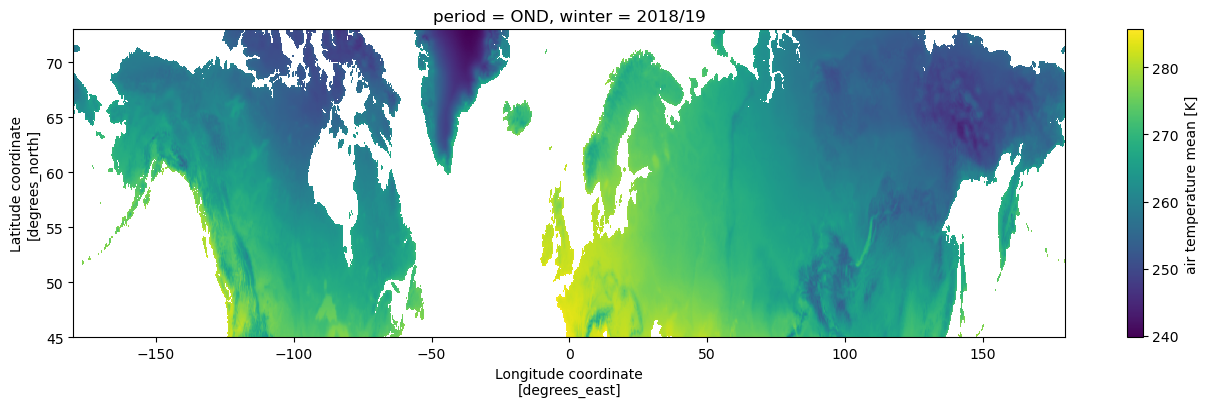

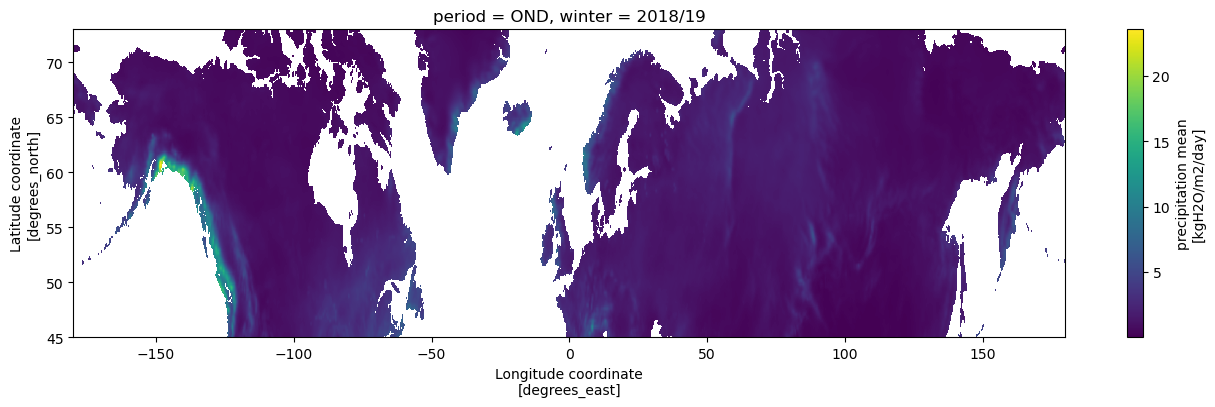

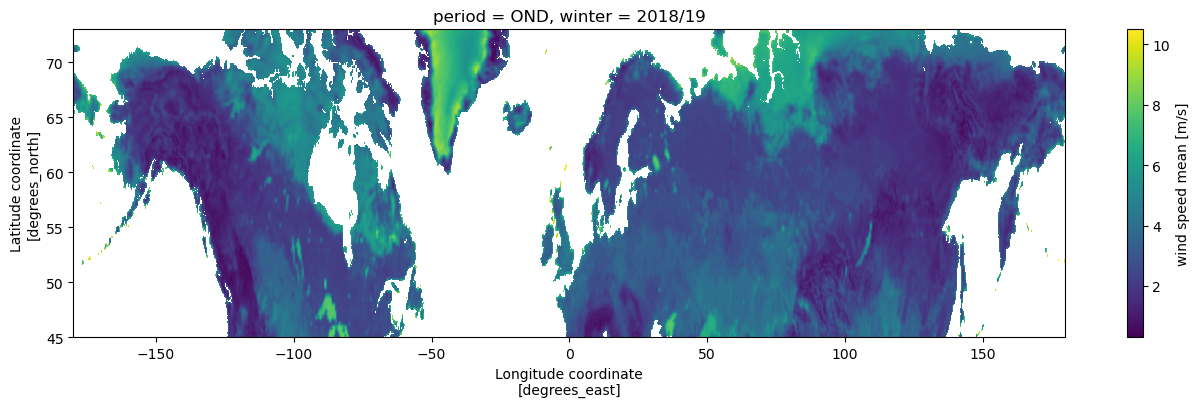

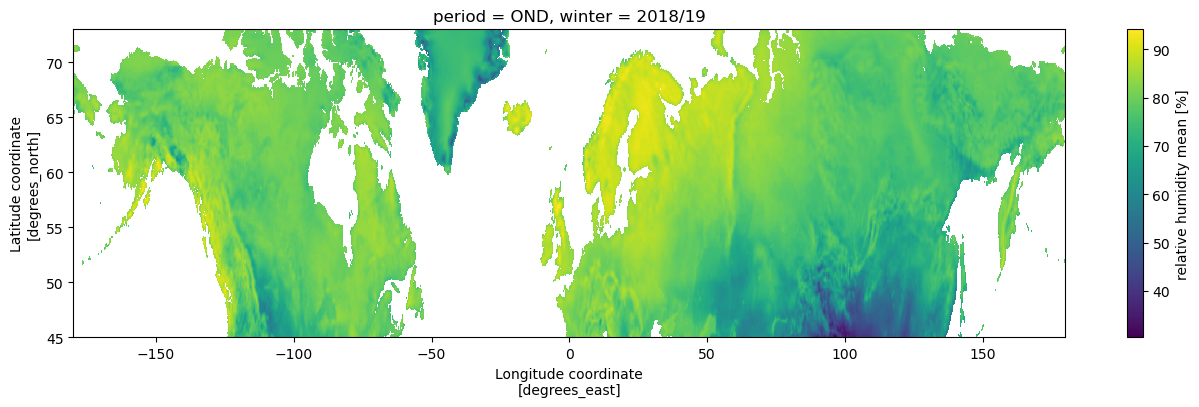

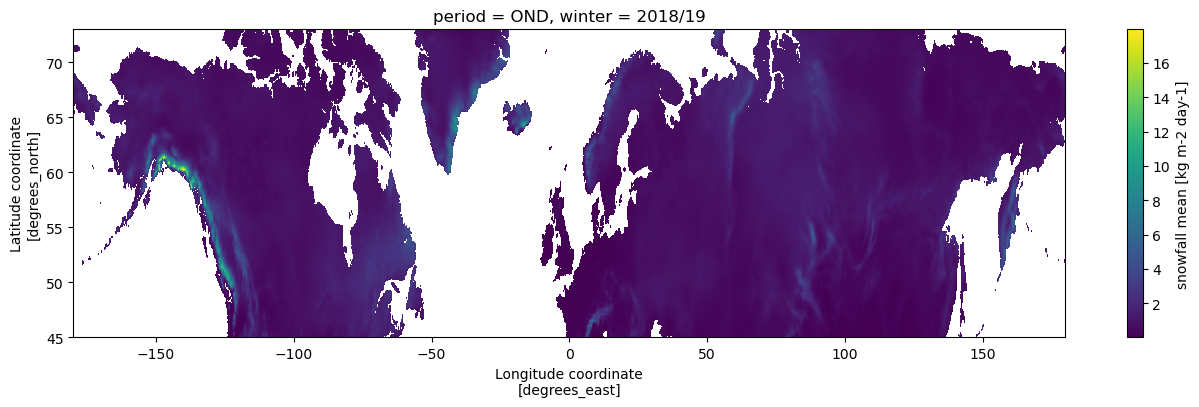

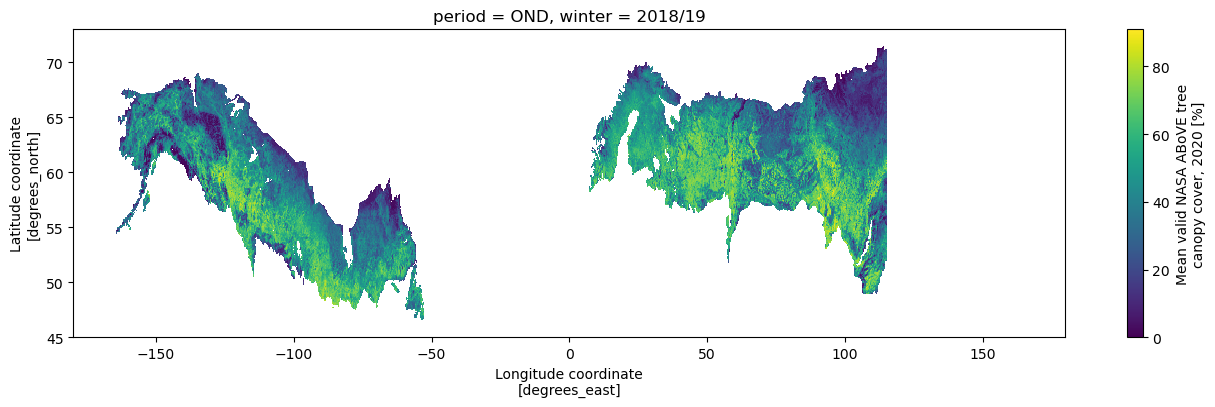

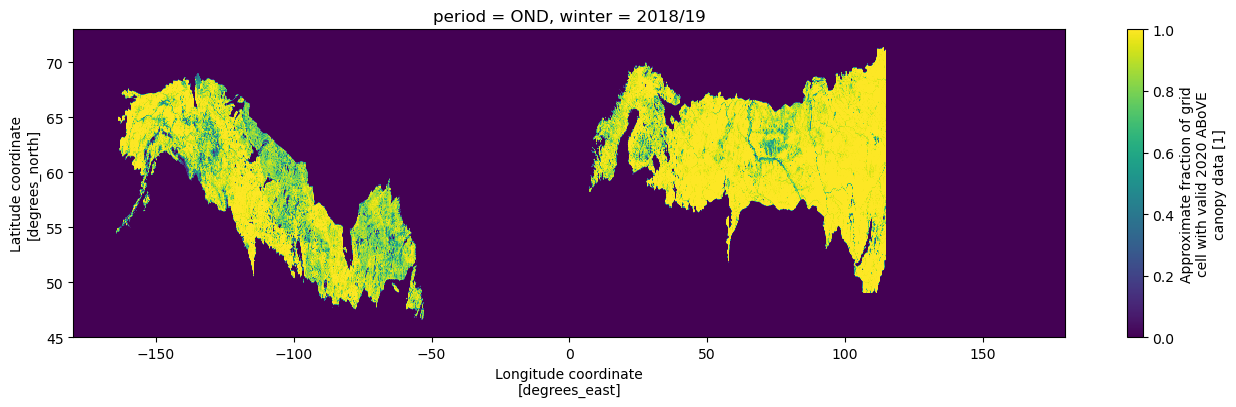

In [2]:
# Define your bounding box limits
min_lat, max_lat = 45, 73

# Create a boolean mask and drop values outside the box
mask = (
    (ds["latitude"] >= min_lat)
    & (ds["latitude"] <= max_lat)
)

ds_cropped = ds.where(mask, drop=True)

PERIOD = 'OND'
WINTER = '2018/19'

from matplotlib import pyplot as plt
fig = plt.figure(figsize=(16,4))
ds.sel(period=PERIOD,winter=WINTER).where(mask, drop=True).air_temperature_mean.plot()
plt.show()
fig = plt.figure(figsize=(16,4))
ds.sel(period=PERIOD,winter=WINTER).where(mask, drop=True).precipitation_mean.plot()
plt.show()
fig = plt.figure(figsize=(16,4))
ds.sel(period=PERIOD,winter=WINTER).where(mask, drop=True).wind_speed_mean.plot()
plt.show()
fig = plt.figure(figsize=(16,4))
ds.sel(period=PERIOD,winter=WINTER).where(mask, drop=True).relative_humidity_mean.plot()
plt.show()
fig = plt.figure(figsize=(16,4))
ds.sel(period=PERIOD,winter=WINTER).where(mask, drop=True).snowfall_mean.plot()
plt.show()
fig = plt.figure(figsize=(16,4))
ds.sel(period=PERIOD,winter=WINTER).where(mask, drop=True).tree_canopy_cover_2020.plot()
plt.show()
fig = plt.figure(figsize=(16,4))
ds.sel(period=PERIOD,winter=WINTER).where(mask, drop=True).tree_canopy_coverage_fraction.plot()
plt.show()

In [ ]:
 vvvvvvvvvv